In [ ]:
import pandas as pd
import graphviz
from graphviz import Digraph
import math
import numpy as np
import random

In [ ]:
import csv
from google.colab import files
uploaded = files.upload()

In [ ]:
File1 = pd.read_csv("Helpdesk_result1.csv")
headers = list(File1.columns.values)
if headers[0] != '0':
  File1 = File1.drop([headers[0]], axis=1)

In [ ]:
class helper:
  def __init__(self):
    self.i= 0

  def multiDimStrToUpper(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.upper() for x in strns])
    return nstring
  def multiDimStrToLower(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.lower() for x in strns])
    return nstring
  def oneDimStrToLower(self, string):
    nstring = []
    for i in range(0, len(string)):
      nstring.append(string[i].lower())
    return nstring

  def grabEventsFromHeader(self, header):
    evs = []
    c = 0
    for ev in header:
      if c > 0:
        try:
          num = int(ev)
        except:
          evs.append(ev)
      c = c + 1
    return evs # return all events
  def rowIsFirst(self, row, activities, headers):
    foundValues = [];
    for i in range(0,len(headers)):
      val = headers[i]
      if val not in activities:
        if not row[val]:
          return True
        else:
          if len(foundValues) > 0:
            return False;
          else:
            foundValues.append(row[val])
    return False

  def rowIsLast(self, row, evName):
    rowEv = row.idxmax()
    try:
      if rowEv.lower() == evName.lower():
        return True
    except:
      return False
    return False

  def divideMatrix(self, matrix): # use the columns to divide the matrix
    headers = list(matrix.columns.values)
    leftHeaders = []
    rightHeaders = []
    for i in range(0,len(headers)):
      ev = headers[i]
      try:
          num = int(ev)
          leftHeaders.append(ev)
      except:
          rightHeaders.append(ev)
    leftData = matrix[leftHeaders]
    rightData = matrix[rightHeaders]
    return [leftData, rightData]

In [ ]:
class resultGraphing:
  def __init__(self):
    self.i= 0
  def decomposeResult(self, results):
    helper_ = helper()
    headers = list(results.columns.values)
    events = helper_.grabEventsFromHeader(headers)
    matrices = []
    matricesLeft = []
    lastIndex = -1
    totalBegin = 0
    ind = 0
    newMatrix = helper_.divideMatrix(results)
    for index, row in results.iterrows():
      ind = index
      if helper_.rowIsFirst(row, events, headers):
        totalBegin = totalBegin + 1
        if lastIndex > -1:
          if lastIndex == 0:
            sequenceList = newMatrix[1].iloc[lastIndex:index, :]
            sequenceListLeft = newMatrix[0].iloc[lastIndex:index, :]
            matrices.append(sequenceList)
            matricesLeft.append(sequenceListLeft)
          else:
            sequenceList = newMatrix[1].iloc[lastIndex+1:index, :]
            sequenceListLeft = newMatrix[0].iloc[lastIndex+1:index, :]
            matrices.append(sequenceList)
            matricesLeft.append(sequenceListLeft)
        if index < 1:
          lastIndex = index
        else:
          lastIndex = index - 1
    sequenceList = newMatrix[1].iloc[lastIndex+1:ind+1, :]
    sequenceListLeft = newMatrix[0].iloc[lastIndex+1:ind+1, :]
    matrices.append(sequenceList)
    matricesLeft.append(sequenceListLeft)
    return matrices, matricesLeft

  # def decomposeResultProbBias(self, results):
  #   helper_ = helper()
  #   headers = list(results.columns.values)
  #   events = helper_.grabEventsFromHeader(headers)
  #   matrices = []
  #   matricesLeft = []
  #   lastIndex = 0
  #   totalBegin = 0
  #   ind = 0
  #   newMatrix = helper_.divideMatrix(results)
  #   for index, row in newMatrix[1].iterrows():
  #     ind = index
  #     rowIsLast = helper_.rowIsLast(row, "end")
  #     if rowIsLast:
  #       sequenceList = newMatrix[1].iloc[lastIndex:index+1, :]
  #       sequenceListLeft = newMatrix[0].iloc[lastIndex:index+1, :]
  #       matrices.append(sequenceList)
  #       matricesLeft.append(sequenceListLeft)
  #       lastIndex = index + 1
  #   return matrices, matricesLeft

  def getEventSequence(self, data, X_label, Y_label):
    currentX_label = ''
    sequences = []
    sequence = []
    for index, row in data.iterrows():
      if currentX_label == row[X_label]:
        sequence.append(row[Y_label])
      else:
        if len(sequence) > 1:
          sequences.append(sequence)
        sequence = []
        sequence.append(row[Y_label])
      currentX_label = row[X_label]
    sequences.append(sequence)
    return sequences
  def rowIsAnewSequence(self, row):
    try:
      return math.isnan(row["1"])
    except:
      return False;
  def chopBySequence(self, matrix):
    startIndex = []
    stopIndex = []
    for index, row in matrix.iterrows():
      if(self.rowIsAnewSequence(row)):
        if(index == 0):
          startIndex.append(index)
        else:
          startIndex.append(index)
          stopIndex.append(index-1)
    stopIndex.append(index)
    return startIndex, stopIndex
  def linkAndProbabilities(self, matrices, count = 0):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    for i in range(0,len(matrices)):
      thisMatrix = matrices[i]
      lastEvent = "Start";
      sequence = []
      for index, row in thisMatrix.iterrows():
        row = pd.to_numeric(row)
        #print(row) # prints the rows
        evName = row.idxmax(axis=1) # picks event with the highest probability
        link = lastEvent + "<-->" + evName
        sequence.append(evName)
        if link not in links:
          if lastEvent != evName:
            links.append(link)
            prob = row[evName] #g
            probabilities.append(prob)
        lastEvent = evName
      # The Last element is End and undesirable
      sequence.pop()
      sequences.append(sequence)
    return links, probabilities, sequences

  def linkAndProbabilities_r(self, matrices, indx = 0):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    for i in range(0,len(matrices)):
      thisMatrix = matrices[i]
      lastEvent = "Start";
      sequence = []
      readEvs = 0
      for index, row in thisMatrix.iterrows():
        row = pd.to_numeric(row)
        #print(row) # prints the rows
        evName = row.idxmax(axis=1) # picks event with the highest probability
        if readEvs == indx:
          if lastEvent.lower() == "end":
            lastEvent = "Start"
          link = lastEvent + "<-->" + evName
          sequence.append(evName)
          if link not in links:
            if lastEvent != evName:
              links.append(link)
              prob = row[evName] #g
              probabilities.append(prob)
        lastEvent = evName
        if evName.lower() == "end":
          readEvs = readEvs + 1
          #print(readEvs)
      # The Last element is End and undesirable
      sequence.pop()
      sequences.append(sequence)
    return links, probabilities, sequences

  def keyAdjust(self, headers, event):
    for e in headers:
      if e.lower() == event.lower():
        return e
    return event

  def linkAndProbabilities_rb(self, eventMatrix, probabilityMatrix, indx = 0):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    eventMatrix = eventMatrix[0]
    probabilityMatrix = probabilityMatrix[0]
    x, y = self.chopBySequence(eventMatrix)
    lastEvent = "Start";
    sequence = []
    readEvs = 0
    if(indx > len(x)):
      raise Exception("Index is out of bound of the sequence count")
    interestingSequenceTable = eventMatrix.loc[x[indx]:y[indx], :]
    interestingSequenceTable = interestingSequenceTable.reset_index(drop=True)
    interestingProbabilityTable = probabilityMatrix.loc[x[indx]:y[indx], :]
    interestingProbabilityTable = interestingProbabilityTable.reset_index(drop=True)
    lookupHeaders = interestingProbabilityTable.columns.values
    for index, row in interestingSequenceTable.iterrows():
      if(index == 0):
        evName = "Start"
      else:
        evName = row[index]
        evName = self.keyAdjust(lookupHeaders, evName)
        probability = interestingProbabilityTable.at[index-1, evName]
        link = lastEvent + "<-->" + evName
        links.append(link)
        probabilities.append(probability)
      sequence.append(evName)
      lastRow = row
      lastEvent = evName
    evName = "END"
    link = lastEvent + "<-->" + evName
    links.append(link)
    probability = interestingProbabilityTable.at[index, evName]
    probabilities.append(probability)
    return links, probabilities, [sequence]


  def drawGraph(self, transitions, probabilities, threshold):
    G = Digraph('process_model', filename='bpi.gv')
    G.attr(rankdir='LR', size='7,5')
    G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
    G.node('Start')
    G.node('END')
    G.attr('node', shape='box', style="bold")
    for i in range(0,len(transitions)):
      fromto = transitions[i].split("<-->")
      if (fromto[0].lower() != "end"):
        # Here Limit or Prune using the threshold
        if probabilities[i] > (threshold*100) or fromto[0].lower() == "start": # This ignores probabilty less than threshold
          G.attr('edge', style="bold", penwidth='3.0', label=str(probabilities[i]))
          G.edge(fromto[0], fromto[1])
    G.view()
    return G


In [ ]:
r = resultGraphing()
a, b = r.decomposeResult(File1)

In [ ]:
link, probabilities, sequences = r.linkAndProbabilities_rb(b, a, 3)
print(link)

['Start<-->Assign seriousness', 'Assign seriousness<-->Take in charge ticket', 'Take in charge ticket<-->Resolve ticket', 'Resolve ticket<-->Closed', 'Closed<-->END']


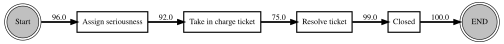

In [ ]:
r.drawGraph(link, probabilities, 0)